# WP12 — İlk gerçek kaynaklı OpenAI yanıtı

Bu notebook kaydedilmiş HTTP200 yanıtını inceler; yeni API isteği/model çalıştırmaz. **Teknik PASS ≠ insan semantik onayı.** Aynı S01 daha önce Gemma yöntem geliştirmesinde kullanılmıştır. Yerel başarısızlıklar, Qwen NOT_RUN ve ilk API hesabının kredi hatası korunur.

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)

Q=ROOT/'reports/qa/WP12/openai_S01_success_review_v1'
F=ROOT/'reports/figures/WP12/openai_S01_success_review_v1'
r=json.loads((Q/'independent_review.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'model':r['model'],'HTTP':r['HTTP_status'],'completion':r['completion_status'],
    'request_id':r['API_request_id'],'HTTP_süre_s':r['latency_HTTP_seconds'],'insan':'PENDING'}]))
display(pd.read_csv(Q/'HTTP_stages.csv'))
print('Modelin özgün JSON mesajı (değiştirilmeden):\n'+(Q/'exact_model_message.txt').read_text(encoding='utf-8'))


Modelin özgün JSON mesajı (değiştirilmeden):
{"result":{"schema_version":"WP12-local-llm-candidate-v2","status":"candidate","refusal_code":null,"items":[{"explanation_tr":"İlacın adı Erythromycin Tablets BP 250 mg’dir ve etkin madde eritromisindir.","source_scope":"product_identity","statement_kind":"identity","evidence_ids":["quote:d6a07837c21263d02077b2e692bb266a46f2ffa230d53d5ebc10988738fe6bbe"]},{"explanation_tr":"Erythromycin Tablets kırmızı renkli, yuvarlak, bikonveks ve enterik kaplı tabletlerdir.","source_scope":"product_identity","statement_kind":"formulation","evidence_ids":["quote:e9288119add1a9a49d1b3353510b966b508729035697e4afe9519f4af95aaeb5"]}],"language":"tr"}}


,model,HTTP,completion,request_id,HTTP_süre_s,insan
0,gpt-5.4-mini-2026-03-17,200,completed,req_9287c40c42ee49169f4b1f217a813aff,3.953,PENDING


,stage,HTTP_status,elapsed_seconds,request_id,HTTP_slot
0,model_access,200,1.297,4ce84978-9496-4034-b74b-9aeca3307137,1
1,input_token_count,200,2.047,req_cd1290d65bcf4666b0710df38fb68eb2,2
2,inference,200,3.953,req_9287c40c42ee49169f4b1f217a813aff,3


**Yorum:** gpt-5.4-mini-2026-03-17 gerçekten completed yanıtı vermiştir. Üç HTTP çağrısının yalnız biri üretimdir; otomatik retry yoktur. 3,953s HTTP süresi ağ/servis toplamıdır; yerel Gemma server-duration ölçüsüyle eş koşullu hız kıyası yapılamaz.

## 1. Gerçek PDF ve iddia karşılaştırması

,physical_page,statement_kind,quote_id,source_quote_exact,model_explanation_exact,agent_note_tr,human_decision
0,1,identity,quote:d6a07837c21263d02077b2e692bb266a46f2ffa230d53d5ebc10988738fe6bbe,"The name of your medicine is Erythromycin Tablets BP 250 mg (referred to as \nErythromycin Tablets in this leaflet). Erythromycin Tablets contain the active ingredient \nerythromycin, which belongs to a group of medicines called macrolide antibiotics. \n \n",İlacın adı Erythromycin Tablets BP 250 mg’dir ve etkin madde eritromisindir.,Tam ürün adı ve etkin madde kaynakta mevcut; macrolide sınıfı aktarılmamış.,PENDING
1,6,formulation,quote:e9288119add1a9a49d1b3353510b966b508729035697e4afe9519f4af95aaeb5,"What Erythromycin Tablets look like and the contents of the pack \nErythromycin Tablets are red coloured, round, biconvex, enteric-coated tablets. \n \nThey are available in blister packs containing 28, 56, 84 and 100 tablets or in containers of \n21, 100, 250, 500 and 1000 tablets. \n \n","Erythromycin Tablets kırmızı renkli, yuvarlak, bikonveks ve enterik kaplı tabletlerdir.",Kırmızı/yuvarlak/bikonveks/enterik kaplı özellikler kaynakta birebir; ambalaj adetleri aktarılmamış.,PENDING


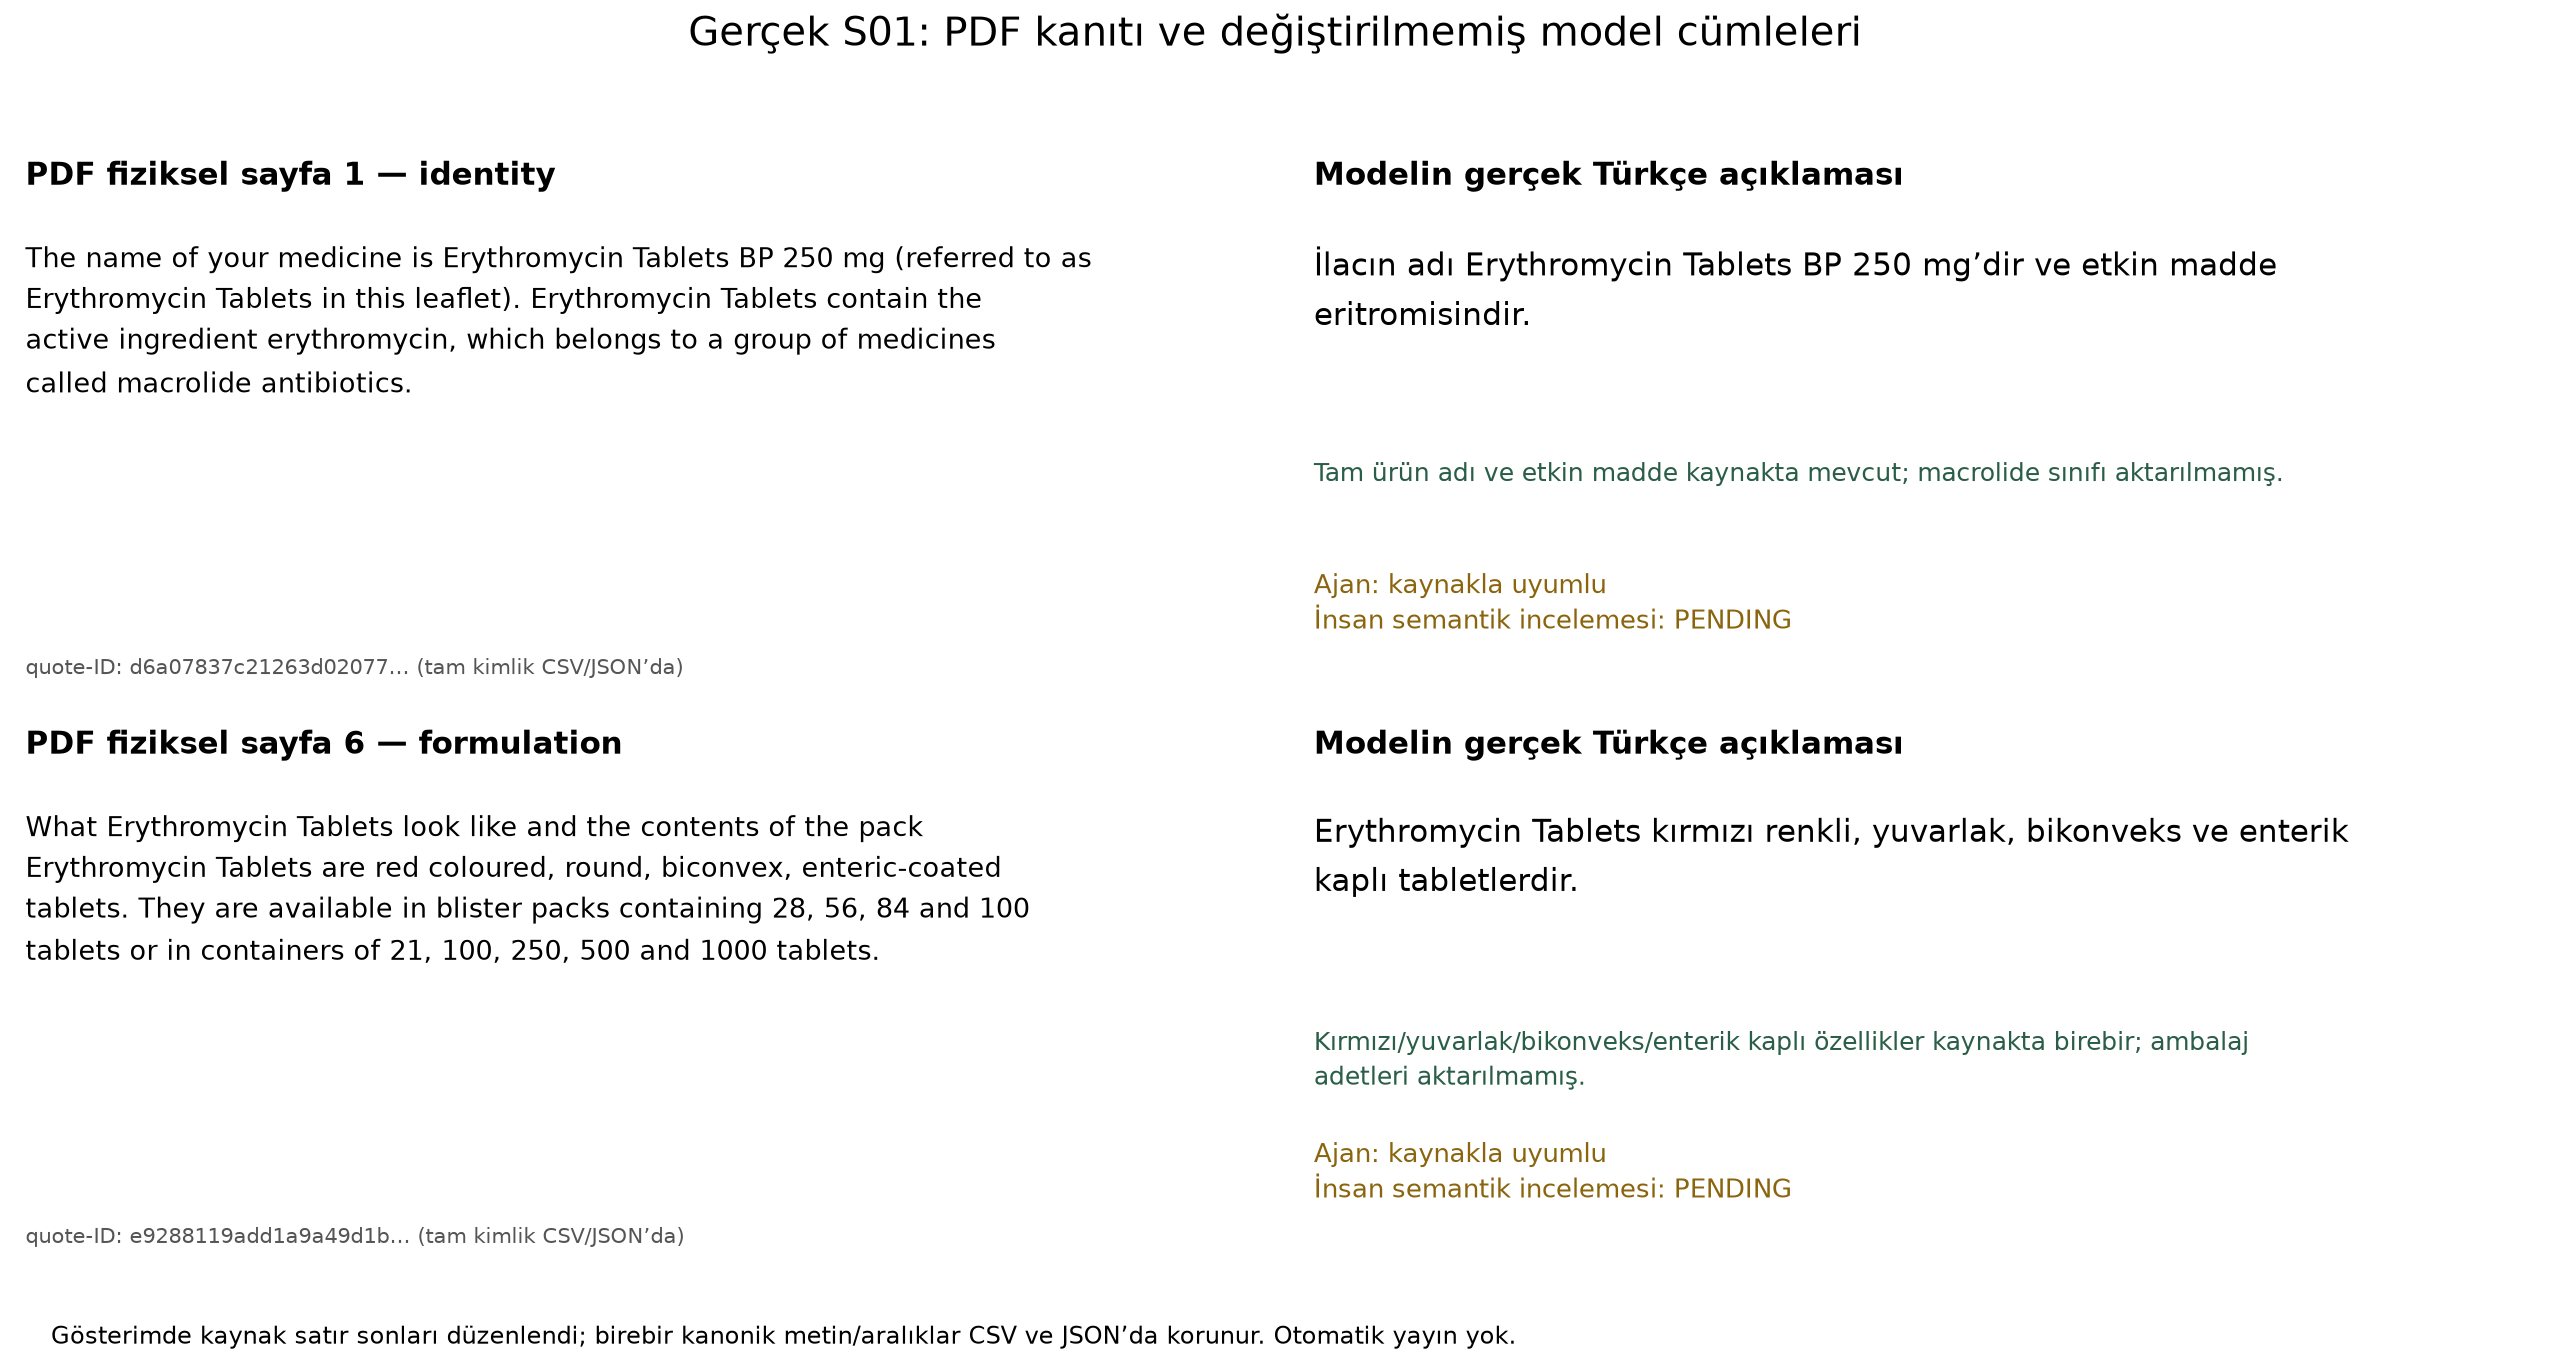

In [2]:

table=pd.read_csv(Q/'source_claim_comparison.csv')
with pd.option_context('display.max_colwidth',None):
    display(table[['physical_page','statement_kind','quote_id','source_quote_exact','model_explanation_exact','agent_note_tr','human_decision']])
from IPython.display import Image
display(Image(filename=str(F/'01_PDF_vs_real_claims.png')))


**Ajan incelemesi:** Tam ürün adı ve etkin madde birinci alıntıdan; kırmızı/yuvarlak/bikonveks/enterik kaplı tablet ifadesi altıncı sayfadaki ikinci alıntıdan desteklenir. Gerçek Türkçe kullanılmış, ürün adı korunmuştur. Yanlış ret veya ek risk/etiket/eşdeğerlik iddiası gözlenmedi. Makrolid sınıfı ve ambalaj adetleri aktarılmamıştır: kısa özetin kapsam notlarıdır; bütün alıntının eksiksiz çevirisi olduğu iddia edilmez. Bu okuma **Codex ajan değerlendirmesidir**, bağımsız insan/klinik doğrulama değildir.

## 2. Bağımsız kullanım ve fiyat hesabı

,input,cached_input,output_total,reasoning_included,total,input_USD,output_USD,token_cost_USD
0,1236,0,217,0,1453,0.000927,0.0009765,0.0019035


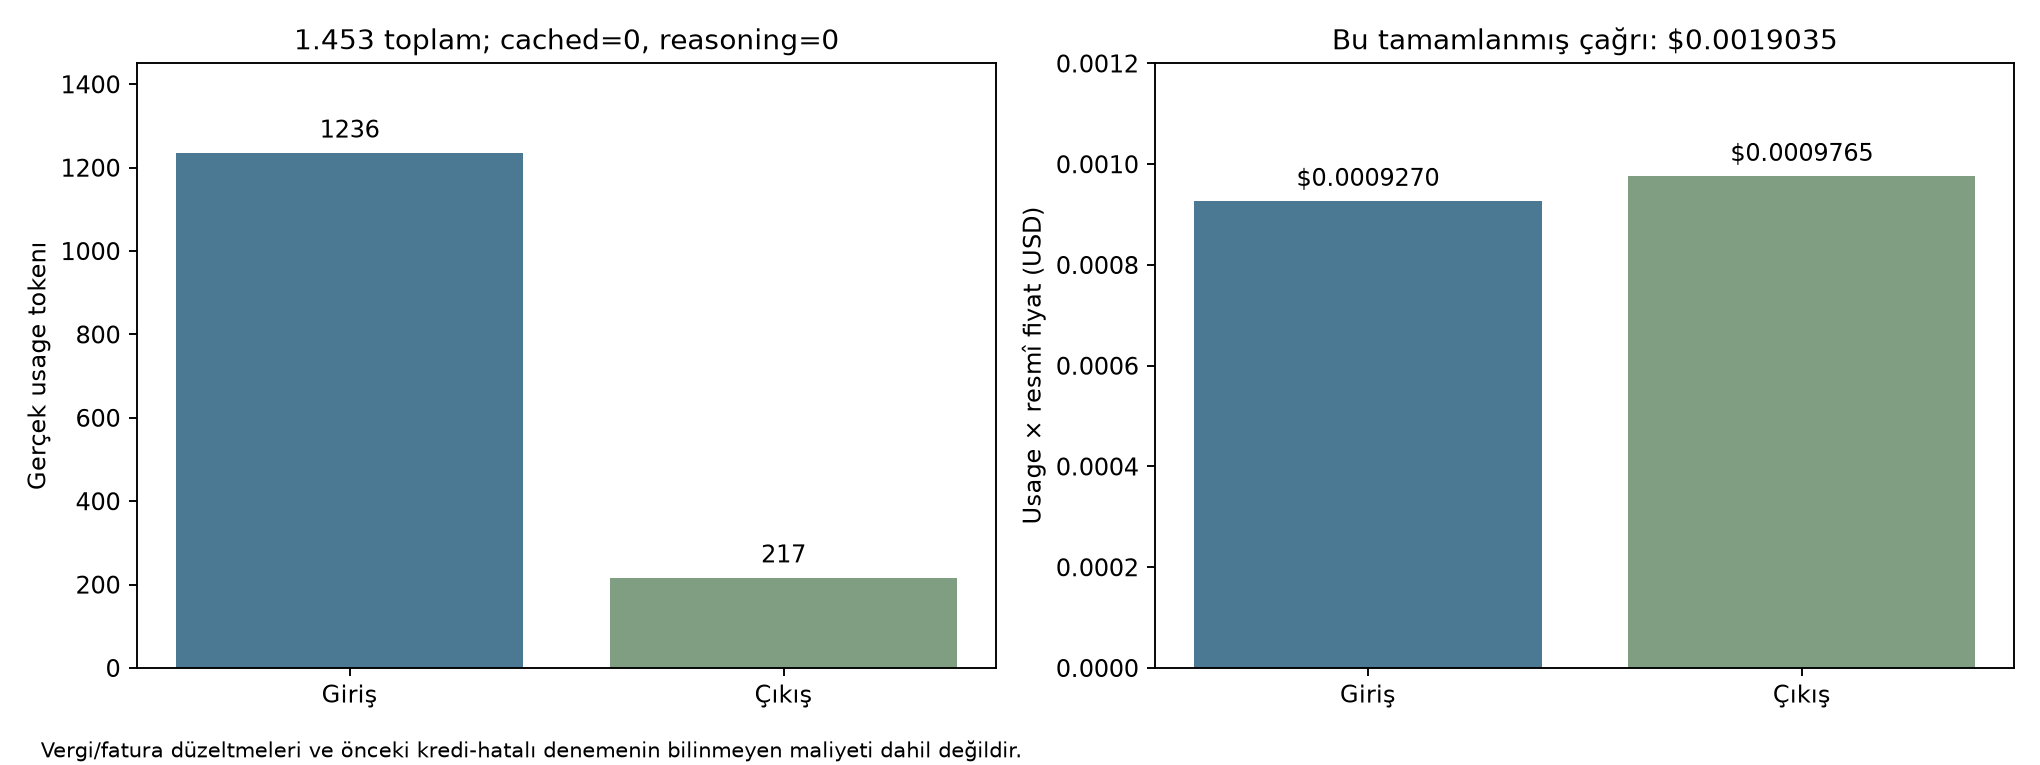

,HTTP_attempt_reservations_all_accounts,inference_reservations_all_accounts,reserved_USD_all_accounts,within_original_pilot_caps,prior_unknown_cost_not_refunded,actual_invoice_cost
0,6,2,0.046,True,True,None


In [3]:

u=r['usage']
display(pd.DataFrame([{'input':u['input_tokens'],'cached_input':u['input_tokens_details']['cached_tokens'],
 'output_total':u['output_tokens'],'reasoning_included':u['output_tokens_details']['reasoning_tokens'],
 'total':u['total_tokens'],'input_USD':r['input_cost_USD'],'output_USD':r['output_cost_USD'],'token_cost_USD':r['usage_token_cost_USD']}]))
display(Image(filename=str(F/'02_actual_usage_and_token_cost.png')))
display(pd.DataFrame([r['aggregate_reservations']]))


**Yorum:**1236×$0,75/1M +217×$4,50/1M =$0,0019035. Cached ve muhakeme alanları gerçekten0; muhakeme output'a ikinci kez eklenmez.217 token, kaynak-ID'leri dahil tüm çıktı JSON'unu kapsar. Bu tutar vergi/fatura düzeltmeleri hariç kullanım-token hesabıdır. Önceki kredi-hatalı isteğin gerçek maliyeti UNKNOWN olduğundan tüm pilotun kesin ücretini bu tutara eşitlemiyoruz. İki hesabın toplam6HTTP/2inference rezervi$0,046 olarak kalır. RAM/VRAM telemetrisi API koşusunda toplanmamıştır; sıfır gibi yazılmaz.

## 3. Bütün gerçek koşular; başarısız ve çalıştırılmayanlar

,model_method,experiment_status,pipeline_terminal_status,independent_content_schema_status,actual_language_agent,source_faithfulness_agent,human_review
0,Gemma V1,FAIL,SCHEMA_OR_SOURCE_VALIDATION_FAILED,PASS,FAIL_ENGLISH,FAIL_CONTRADICTED,PENDING
1,Gemma V2,FAIL,TOKEN_COUNT_ALIGNMENT_FAILED,PASS,FAIL_ENGLISH,CORE_SUPPORTED_OMISSIONS,PENDING
2,Qwen3 4B,NOT_RUN,BLOCKED_HOST_RAM_AND_TOKEN_API_PREREQUISITES,NOT_RUN,NOT_RUN,NOT_RUN,PENDING
3,OpenAI / first account,API_BILLING_BLOCKED_NO_MODEL_OUTPUT,HTTP429 credit_balance_exhausted,NOT_EVALUABLE,NOT_EVALUABLE,NOT_EVALUABLE,PENDING_NO_OUTPUT
4,gpt-5.4-mini-2026-03-17 / corrected account,COMPLETED_PENDING_HUMAN,HTTP200 completed,PASS,TURKISH_SUPPORTED_SOURCE_PROPER_NAMES_RETAINED,SUPPORTED_FOR_TWO_RETURNED_ITEMS,PENDING


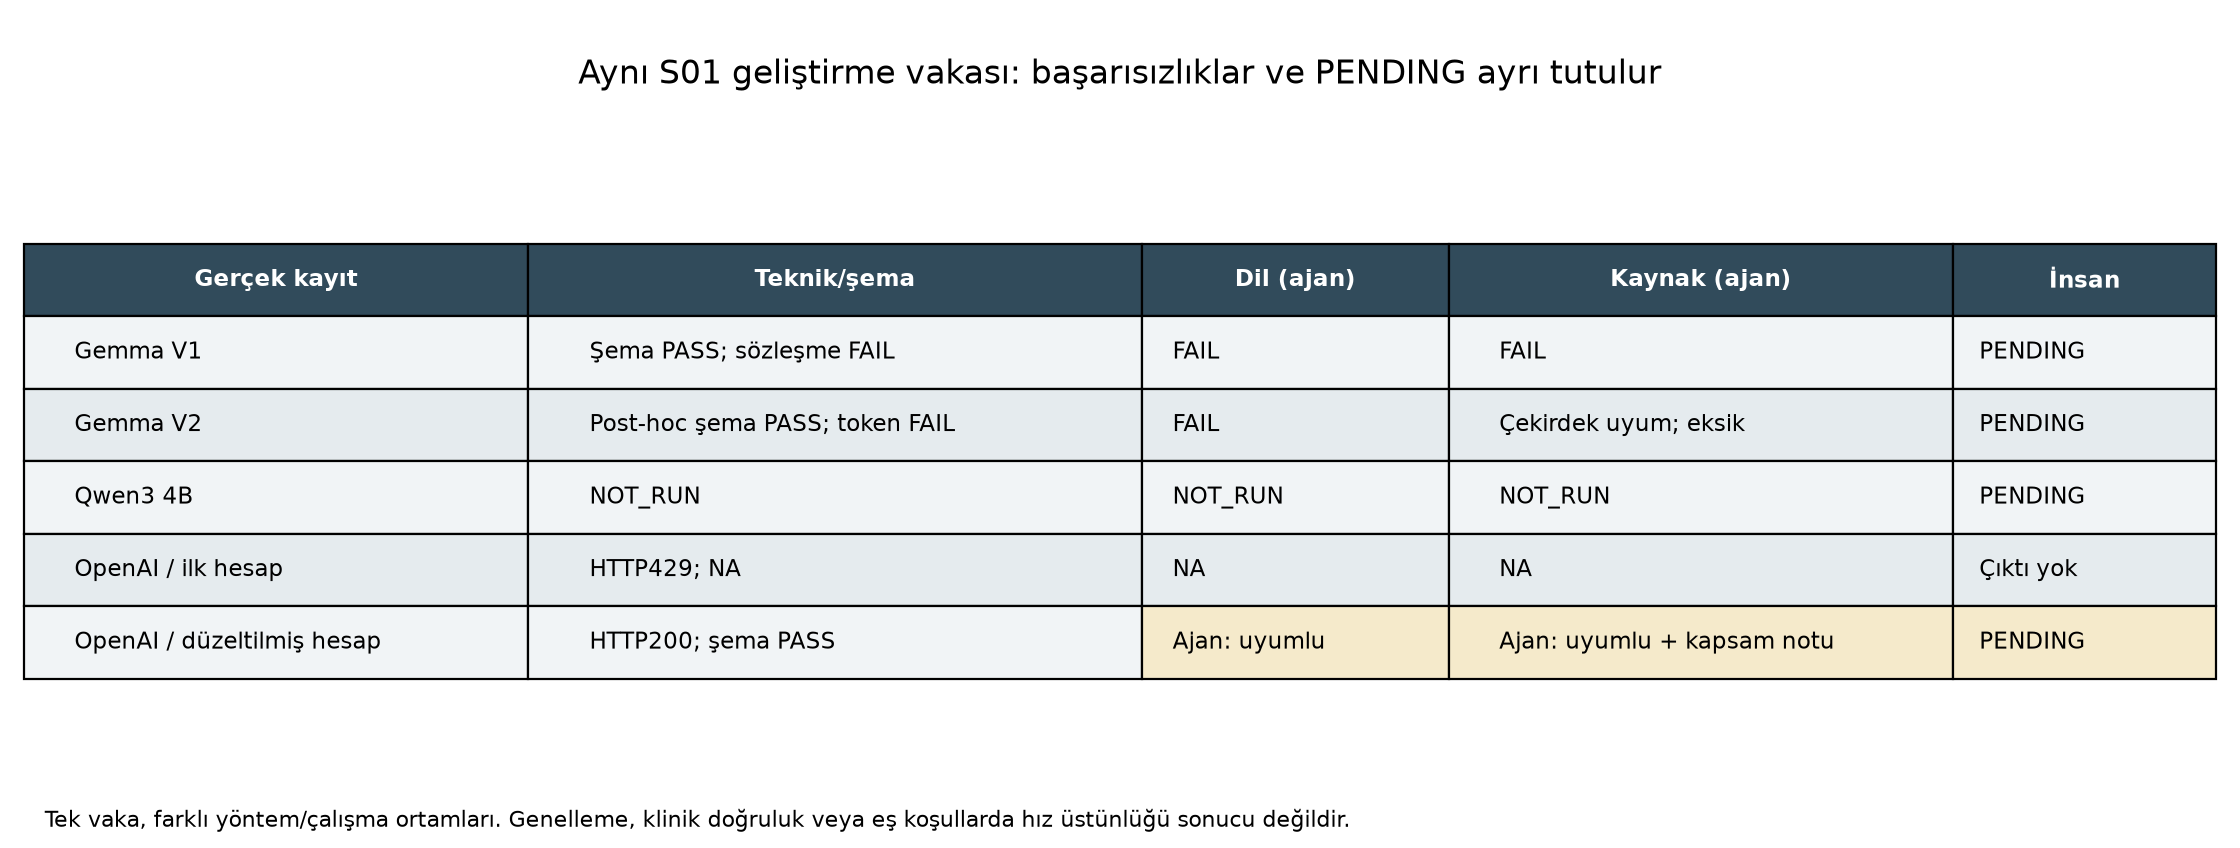

In [4]:

c=pd.read_csv(Q/'all_real_runs_comparison.csv')
display(c[['model_method','experiment_status','pipeline_terminal_status','independent_content_schema_status','actual_language_agent','source_faithfulness_agent','human_review']])
display(Image(filename=str(F/'03_real_comparison_statuses.png')))


**Yorum:** Bu tablo nitel, tek-vaka geliştirme karşılaştırmasıdır; başarı yüzdesi veya bağımsız benchmark değildir. Gemma V2'nin orijinal token hatası post-hoc şema PASS ile silinmez. İlk OpenAI kredi hatası modelin açıklama kalitesi olarak FAIL sayılmaz. Qwen çalıştırılmadığı için NOT_RUN kalır. Yeni iki Türkçe item ajan okumasında uyumlu; insan onayı PENDING.

## 4. Kaynak ve teknik kontrol kanıtları

In [5]:

display(pd.DataFrame([{'kontrol':k,'sonuç':v} for k,v in r['checks'].items()]))
display(pd.DataFrame(r['source_page_checks']))
display(pd.DataFrame([json.loads((Q/'test_summary.json').read_text(encoding='utf-8'))]))
print('İnsan kararı: PENDING; tekrar kararlılığı: tek tamamlanmış yanıtla değerlendirilemez.')


İnsan kararı: PENDING; tekrar kararlılığı: tek tamamlanmış yanıtla değerlendirilemez.


,kontrol,sonuç
0,run_hashes_all_match,True
1,run_inventory_matches_manifest,True
2,record_raw_and_prompt_hashes_match,True
3,same_source_request_as_first_failed_account_byte_for_byte,True
4,frozen_request_and_source_unchanged,True
5,all_HTTP_200,True
6,completed_expected_model,True
7,strict_parsed_raw_matches_saved_JSON,True
8,independent_validator_matches_saved_review,True
9,no_tools_or_GNN_prediction,True


,physical_page,quote_id,full_page_text_matches_stored,fresh_page_range_equals_quote,quote_sha256_matches,full_page_codepoints
0,1,quote:d6a07837c21263d02077b2e692bb266a46f2ffa230d53d5ebc10988738fe6bbe,True,True,True,2352
1,6,quote:e9288119add1a9a49d1b3353510b966b508729035697e4afe9519f4af95aaeb5,True,True,True,1860


,tests,returncode,new_API_requests
0,12,0,0


**Durma noktası:** Fiziksel1/6 tam sayfa metinleri yeniden salt okunur doğrulanıp görsel incelendi; kaynak PDF ve eski artefaktlar değiştirilmedi. İnsan formu ayrı QA kaydıdır; kaynak/model dosyası üzerinde karar değişikliği yapılmaz. Doxycycline sınıf/BUN istisnası, bilinmeyen sıklık ve kaynak dışı görev senaryoları bu S01 sonucuyla doğrulanmış sayılmaz. Kalan pilot için kullanıcı sonuç değerlendirmesi gerekir; 10 toplamHTTP tavanında yalnız4 HTTP kapasitesi kalmıştır. Bu tur başka senaryo,19×3, eğitim, yayın veya WP13 yoktur.

[Resmî model/fiyat](https://developers.openai.com/api/docs/models/gpt-5.4-mini); kanonik kaynak: kullanıcı tarafından sağlanmış pil.502.pdf, fiziksel1 ve6.